# El protocolo con sitio fuera y un criterio predeclarado: lo que revela una campaña fuera y una división aleatoria esconde

**Nivel 4: Más allá del estado del arte** · Requiere: 04-benchmark-protocol/02-scores-the-null-and-the-interval, 04-benchmark-protocol/03-placing-a-published-score-in-its-own-protocol · Tiempo de lectura: unos 30 minutos

## Objetivos

La afirmación BS-1 del producto es un protocolo, no un modelo: el nivel aprendido se juzga con campañas completas fuera, con intervalos que remuestrean campañas, y con un criterio escrito antes de la ejecución y fijado por un hash. Este cuaderno reúne la evidencia de esa afirmación en todos los brazos y muestra lo que el protocolo revela.

Al terminar habrá:

- puesto lado a lado la mediana de la división aleatoria y el puntaje con sitio fuera de cada brazo, desde el benchmark versionado, y recalculado un brazo desde cero;
- leído los intervalos con remuestreo de sitios de cada brazo y visto cuáles, si alguno, quedan sobre cero;
- visto, sitio por sitio, dónde falla un brazo aprendido con el sitio fuera, y qué frase del criterio registra que se cambió una vez tras ver un resultado.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| El benchmark versionado: tres protocolos, cada brazo, los intervalos con remuestreo de sitios, los errores por sitio y el veredicto | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json` |

## Método

El protocolo tiene cuatro partes, cada una una decisión que inspeccionan las celdas siguientes:

1. **Dejar la campaña fuera.** Un pliegue por sitio, los otros nueve en entrenamiento, el nulo reajustado en cada pliegue.
2. **Informar la brecha.** Para cada brazo, la mediana de 100 sorteos aleatorios 80/20 menos el puntaje agrupado con sitio fuera, de modo que el costo del protocolo es un número.
3. **Remuestrear la unidad correcta.** Los intervalos sortean campañas, no tiros, 2000 veces.
4. **Declarar primero el criterio.** La frase que decide si el nivel aprendido generaliza está fija, y su hash está fijado en la suite de pruebas del motor; la documentación de Fragmenta registra su único cambio, hecho tras una primera ejecución en la que la regla de solo margen declaró éxito para un brazo que lo hacía peor que predecir una constante.

## Estado del arte

- Los predictores aprendidos publicados sobre este corpus (Sui et al. 2025, https://doi.org/10.3390/app15031254) informan un puntaje de una sola división aleatoria 80/20.
- La base de investigación del SDD anota que los resúmenes de los estudios de predictores aprendidos (Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3; Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0) no dicen que se haya dejado fuera una mina completa, y que los predictores publicados son de un solo sitio.
- El remuestreo agrupado es el remedio establecido cuando los datos son dependientes (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## Más allá del estado del arte

### Paso 1: el costo del protocolo, brazo por brazo

El benchmark versionado guarda, para cada brazo, la mediana de sus 100 sorteos aleatorios y su puntaje agrupado con sitio fuera. La celda imprime ambos y su diferencia. Para los brazos aprendidos la mediana de los sorteos aleatorios es un puntaje al estilo publicado; el puntaje con sitio fuera es con el que el producto encabeza.

In [2]:
# Importaciones, y luego la mediana de la división aleatoria, el puntaje con sitio fuera y su diferencia para cada brazo del benchmark versionado
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
random_arms = benchmark["protocols"]["random-8020"]["arms"]
loso_arms = benchmark["protocols"]["leave-one-site-out"]["arms"]
verdict = benchmark["verdict"]
rows = []
for name, entry in loso_arms.items():
    if entry["tier"] == "control" and name == "oracle":
        continue
    median = random_arms[name]["repeats"].get("median")
    held = entry["r2_identity"]
    if held is not None and median is not None:
        rows.append((name, entry["tier"], median, held, median - held))
rows.sort(key=lambda r: -r[4])
print(f"{'brazo':<22}{'nivel':<12}{'mediana aleatoria':>20}{'sitio fuera':>14}{'brecha':>9}")
for name, tier, median, held, gap in rows:
    print(f"{name:<22}{tier:<12}{median:>20.3f}{held:>14.3f}{gap:>9.3f}")
print("brecha mediana sobre los brazos aprendidos =", round(verdict["median_protocol_gap"], 4), "| brazos aprendidos:", verdict["n_learned_arms"])

brazo                 nivel          mediana aleatoria   sitio fuera   brecha
svr-poly              learned                    0.395        -4.546    4.940
refitted-regression   statistical                0.686        -4.075    4.760
svr-rbf               learned                    0.665        -0.387    1.052
published-neural-net  learned                    0.362        -0.626    0.988
random-forest         learned                    0.749        -0.231    0.981
xgboost               learned                    0.704        -0.034    0.738
stacking              learned                    0.703        -0.035    0.738
null                  control                   -0.036        -0.216    0.180
kuznetsov-capped      classical                  0.399         0.352    0.047
kuznetsov-transfer    classical                  0.312         0.298    0.014
published-regression  statistical                0.805         0.802    0.003
kuznetsov             classical                  0.303         0

La celda siguiente dibuja la brecha de los brazos cuyo puntaje más cambia el protocolo, de modo que los brazos clásicos y estadísticos (que no aprenden nada de la campaña) puedan compararse con los aprendidos.

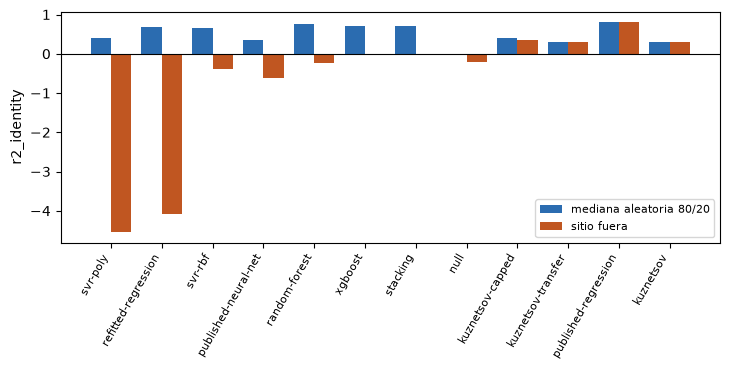

In [3]:
# Mediana de la división aleatoria contra puntaje con sitio fuera, un par de barras por brazo
shown = [r for r in rows if r[2] > -1 and r[3] > -5]
fig, ax = plt.subplots(figsize=(7.4, 3.8))
x = np.arange(len(shown))
ax.bar(x - 0.2, [r[2] for r in shown], 0.4, color="#2b6cb0", label="mediana aleatoria 80/20")
ax.bar(x + 0.2, [r[3] for r in shown], 0.4, color="#c05621", label="sitio fuera")
ax.set_xticks(x, [r[0] for r in shown], rotation=60, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("r2_identity")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Paso 2: recalcular un brazo desde cero

Para confirmar que la tabla no se limita a leerse de un archivo, la celda recalcula el brazo de gradient boosting: 100 sorteos aleatorios y los diez pliegues, y compara la mediana y la brecha con las versionadas.

In [4]:
# Gradient boosting: 100 sorteos aleatorios y diez pliegues con sitio fuera, reajustados aquí
train = bf.load_training_corpus()
factory = bf.default_arms()["xgboost"]
draws = []
for split in bf.repeated_random_splits(train, n_repeats=100, seed=0):
    arm = factory().fit(split.train)
    draws.append(bf.score(split.test, arm.predict(split.test)).r2_identity)
tested, predicted = [], []
for split in bf.leave_one_site_out(train):
    arm = factory().fit(split.train)
    tested += list(split.test)
    predicted += arm.predict(split.test)
held_out = bf.score(tested, predicted).r2_identity
print(f"xgboost: mediana aleatoria {np.median(draws):.4f} (versionada {random_arms['xgboost']['repeats']['median']:.4f}) | sitio fuera {held_out:.4f} (versionado {loso_arms['xgboost']['r2_identity']:.4f})")
print(f"brecha {np.median(draws) - held_out:.4f} (versionada {verdict['protocol_gap_random_minus_grouped']['xgboost']:.4f})")

xgboost: mediana aleatoria 0.7040 (versionada 0.7040) | sitio fuera -0.0342 (versionado -0.0342)
brecha 0.7382 (versionada 0.7382)


### Paso 3: los intervalos que remuestrean campañas

El veredicto guarda un intervalo de 95 por ciento con remuestreo de sitios por brazo y conjunto de filas. La celda los lista para `all` y `geometry` y marca los que tienen su extremo inferior sobre cero. El brazo en muestra (la regresión publicada, ajustada por su fuente en estos 97 tiros) se señala, porque ninguna división puede esconderle un tiro.

In [5]:
# Intervalos con remuestreo de sitios para cada brazo en ambos conjuntos de filas, señalando un extremo inferior sobre cero y el brazo en muestra
in_sample = {name for name, *_ in verdict["in_sample_arms"]}
print(f"{'brazo':<22}{'todos 97':>22}{'geometría 91':>24}  sobre cero")
for name, both in verdict["intervals_95"].items():
    if both["all"] is None:
        continue  # an arm with no size to score has no interval
    flag = " (en muestra)" if name in in_sample else ""
    above = [s for s in ("all", "geometry") if both[s][0] > 0]
    print(f"{name:<22}{both['all'][0]:>10.2f} a {both['all'][1]:>5.2f}{both['geometry'][0]:>12.2f} a {both['geometry'][1]:>5.2f}  {above if above else '-'}{flag}")
print("brazos con un intervalo sobre cero, sin los brazos en muestra:", verdict["arms_with_interval_above_zero"])

brazo                               todos 97            geometría 91  sobre cero
kuznetsov                  -0.96 a  0.70       -0.97 a  0.69  -
kuznetsov-capped           -0.95 a  0.74       -0.96 a  0.73  -
kuznetsov-transfer         -1.10 a  0.72       -1.10 a  0.71  -
published-neural-net       -3.35 a  0.01       -3.42 a  0.09  -
published-regression        0.57 a  0.90        0.50 a  0.88  ['all', 'geometry'] (en muestra)
random-forest              -2.78 a  0.38       -2.88 a  0.40  -
refitted-regression       -19.48 a  0.02      -21.92 a  0.09  -
stacking                   -2.25 a  0.42       -1.81 a  0.54  -
svr-poly                  -16.24 a -0.83      -17.18 a -0.95  -
svr-rbf                    -1.61 a -0.06       -1.86 a -0.07  -
xgboost                    -2.23 a  0.42       -1.78 a  0.53  -
brazos con un intervalo sobre cero, sin los brazos en muestra: []


### Paso 4: dónde falla un brazo con el sitio fuera

Un puntaje agrupado esconde en qué campañas se equivoca el modelo. El benchmark guarda, para cada brazo y sitio, el tamaño medio predicho y el medido. La celda imprime el brazo de gradient boosting sitio por sitio y dibuja lo predicho contra lo medido.

sitio             n      medido (m)      predicho (m)   sesgo (m)
Miami             6           0.080             0.378      +0.298
Mrica            11           0.166             0.257      +0.090
Akdaglar         22           0.171             0.245      +0.074
Ozmert            7           0.191             0.167      -0.024
Soma              7           0.224             0.126      -0.099
Murgul            7           0.311             0.672      +0.360
Enusa            12           0.396             0.463      +0.067
Dongri-Buzurg     9           0.413             0.260      -0.153
Reocin-UG         6           0.593             0.553      -0.040
Reocin           10           0.616             0.382      -0.234


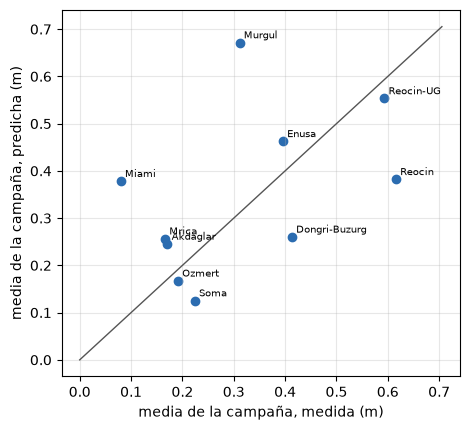

In [6]:
# El tamaño medio medido y predicho por sitio del brazo de gradient boosting con sitio fuera
per_site = loso_arms["xgboost"]["per_site"]
print(f"{'sitio':<16}{'n':>3}{'medido (m)':>16}{'predicho (m)':>18}{'sesgo (m)':>12}")
for site, entry in sorted(per_site.items(), key=lambda kv: kv[1]["mean_measured_m"]):
    print(f"{site:<16}{entry['n_blasts']:>3}{entry['mean_measured_m']:>16.3f}{entry['mean_predicted_m']:>18.3f}{entry['bias_m']:>+12.3f}")
measured = [e["mean_measured_m"] for e in per_site.values()]
predicted_means = [e["mean_predicted_m"] for e in per_site.values()]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(measured, predicted_means, color="#2b6cb0")
for site, x, y in zip(per_site, measured, predicted_means):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
limit = max(measured + predicted_means) * 1.05
ax.plot([0, limit], [0, limit], color="#555", lw=1)
ax.set_xlabel("media de la campaña, medida (m)")
ax.set_ylabel("media de la campaña, predicha (m)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Resultados

**Cada brazo aprendido paga el protocolo.** Los brazos aprendidos pierden entre cerca de 0,7 y 5 de varianza explicada cuando se deja la campaña fuera, con una brecha mediana cercana a 0,98 en los seis, mientras que los brazos clásicos, que no aprenden nada de las filas de entrenamiento, pierden casi nada. La brecha es por tanto una propiedad de aprender de sitios, no de la dificultad de este corpus. El brazo de gradient boosting recalculado iguala al versionado hasta el último dígito.

**Ningún brazo tiene un intervalo sobre cero salvo el ajustado por su fuente en estos tiros.** Con intervalos que remuestrean campañas, la ecuación clásica y la mayoría de los brazos aprendidos abarcan el cero con amplio margen, y los dos brazos de vectores de soporte quedan por completo bajo él (peores que predecir la media). El intervalo de la regresión publicada está sobre cero, pero su fuente la ajustó con los 97 tiros, así que el puntaje con sitio fuera es un ajuste en muestra y el veredicto la lista aparte.

**La falla tiene nombres.** La tabla por sitio muestra al brazo con sitio fuera sobrepredecir las campañas más finas (Miami por 0,30 m) y subpredecir las más gruesas (Reocin por 0,23 m): las predicciones regresan hacia la media de entrenamiento, que la campaña excluida entonces no comparte. La excepción es Murgul, sobrepredicha por 0,36 m aunque es una campaña de tamaño medio. La regresión hacia la media es el mismo efecto que infla el margen del nulo.

**Lo que compra el protocolo.** El lector obtiene un puntaje que responde la pregunta del profesional, el costo de la pregunta como número, un intervalo que no exagera la evidencia, y un criterio cuya redacción no puede ajustarse tras ver los datos. Lo que no puede es dar a los modelos una habilidad que no tienen: con diez campañas, ningún brazo fuera de los que están en muestra se separa de predecir la media del corpus.

## Resumen

- El protocolo convierte el costo de la pregunta del profesional en un número: los brazos aprendidos pierden la mayor parte de su puntaje de división aleatoria cuando se deja una campaña fuera, y los clásicos no (afirmación BS-1).
- Los intervalos que remuestrean campañas no dejan ningún brazo sobre cero salvo el ajustado por su fuente en estos tiros.
- El criterio está fijado por un hash y su único cambio está registrado; el veredicto se informa en ambos conjuntos de filas.
- Siguiente: el tema 05 abre los propios brazos aprendidos y por qué cada uno se abstiene donde lo hace.

## Referencias

- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (el protocolo de división aleatoria)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (remuestreo agrupado bajo dependencia)
- Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3 (predictores aprendidos, solo el resumen)
- Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0 (predictores aprendidos, solo el resumen)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `docs/protocols/04_criterion-and-row-sets.md` de este repositorio, para la redacción del criterio, su hash y su historia
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/